# 🗑️ MobileNetV2 for Multiclass Garbage Image Classification
## CAK4WBB3 – Computer Vision | Task 1: CNN Architecture Observation

---

| Item | Details |
|------|---------|
| **Architecture** | MobileNetV2 (Pretrained on ImageNet) |
| **Framework** | PyTorch |
| **Classes** | cardboard · glass · metal · paper · plastic |
| **Task** | Multiclass Image Classification |
| **Split** | 70% Train / 15% Validation / 15% Test (stratified) |
| **Random Seed** | 42 (reproducible) |

---


## 1. Project Introduction and Objectives

### Background
Garbage classification is a practical computer vision problem with direct environmental impact.
Automating the identification of recyclable materials—cardboard, glass, metal, paper, and
plastic—can improve recycling efficiency and reduce reliance on manual sorting labor.

### Why MobileNetV2?
MobileNetV2 is a lightweight convolutional neural network designed specifically for mobile and
resource-constrained environments. Through **transfer learning** from ImageNet pretrained weights,
strong classification performance can be achieved even with a relatively small dataset (~2,390 images)
and without GPU hardware.

### Objectives
1. Apply MobileNetV2 transfer learning to classify five garbage categories.
2. Evaluate performance using accuracy, macro/weighted precision, recall, and F1-score.
3. Analyze computational efficiency: total parameters, model size, inference latency, and throughput.
4. Visualize training dynamics, class distribution, confusion matrix, and prediction examples.
5. Assess MobileNetV2's suitability for resource-constrained garbage classification deployment.


## 2. Environment and Dependency Checks

In [1]:
import subprocess, sys, importlib

def ensure(package, import_as=None, pip_name=None):
    name = import_as or package
    pip  = pip_name  or package
    try:
        m   = importlib.import_module(name)
        ver = getattr(m, '__version__', 'installed')
        print(f"  ✅  {package:<22} {ver}")
    except ImportError:
        print(f"  📦  Installing {package} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip])
        m   = importlib.import_module(name)
        ver = getattr(m, '__version__', 'installed')
        print(f"  ✅  {package:<22} {ver}  ← just installed")

print("Checking dependencies ...")
ensure("torch")
ensure("torchvision")
ensure("numpy")
ensure("pandas")
ensure("matplotlib")
ensure("seaborn")
ensure("scikit-learn", "sklearn")
ensure("Pillow", "PIL")
ensure("opencv-python", "cv2")

import torch
print(f"\nPyTorch : {torch.__version__}")
print(f"CUDA    : {torch.cuda.is_available()}")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(f"GPU     : {torch.cuda.get_device_name(0)}")
else:
    print("GPU     : Not available — training on CPU")
print(f"Device  : {DEVICE}")
print(f"Python  : {sys.version.split()[0]}")


Checking dependencies ...
  ✅  torch                  2.14.1+cpu
  ✅  torchvision            0.29.2+cpu
  ✅  numpy                  2.4.6
  ✅  pandas                 3.0.3
  ✅  matplotlib             3.11.0
  ✅  seaborn                0.13.2
  ✅  scikit-learn           1.9.0
  ✅  Pillow                 12.2.0
  ✅  opencv-python          5.0.0

PyTorch : 2.14.1+cpu
CUDA    : False
GPU     : Not available — training on CPU
Device  : cpu
Python  : 3.13.2


## 3. Imports and Global Settings

In [2]:
# Standard library
import os, time, warnings
warnings.filterwarnings('ignore')

# Numerical / data
import numpy as np
import pandas as pd

# Visualization
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

# Image processing
from PIL import Image

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Torchvision
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility
RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)

print("All imports successful.")
print(f"  PyTorch     : {torch.__version__}")
print(f"  torchvision : {torchvision.__version__}")
print(f"  NumPy       : {np.__version__}")
print(f"  pandas      : {pd.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")


All imports successful.
  PyTorch     : 2.14.1+cpu
  torchvision : 0.29.2+cpu
  NumPy       : 2.4.6
  pandas      : 3.0.3
  matplotlib  : 3.11.0


## 4. Dataset Path Configuration

Adjust `DATASET_ROOT` below if your dataset lives in a different directory.
All output paths are derived automatically.


In [3]:
# ─── Dataset ─────────────────────────────────────────────────────────────────
DATASET_ROOT = r"c:\Users\Asus\Downloads\viskom\Garbage classification\Garbage classification"
CLASSES      = ['cardboard', 'glass', 'metal', 'paper', 'plastic']
NUM_CLASSES  = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}
IDX_TO_CLASS = {i: cls for cls, i in CLASS_TO_IDX.items()}

# ─── Hyperparameters ─────────────────────────────────────────────────────────
IMG_SIZE       = 224
BATCH_SIZE     = 32
NUM_EPOCHS_P1  = 15      # Phase 1: train head with frozen backbone
NUM_EPOCHS_P2  = 10      # Phase 2: fine-tune upper backbone layers
LR_P1          = 1e-3
LR_P2          = 1e-4
WEIGHT_DECAY   = 1e-4
EARLY_STOP_PAT = 5

# ImageNet normalization (required for MobileNetV2 pretrained weights)
IMAGENET_MEAN  = [0.485, 0.456, 0.406]
IMAGENET_STD   = [0.229, 0.224, 0.225]

# Split fractions
TRAIN_FRAC = 0.70
VAL_FRAC   = 0.15
TEST_FRAC  = 0.15

# ─── Output directories ───────────────────────────────────────────────────────
# Outputs go to  viskom/outputs/
OUTPUT_DIR = os.path.normpath(
    os.path.join(DATASET_ROOT, "..", "..", "outputs"))
MODEL_DIR  = os.path.join(OUTPUT_DIR, "mobilenetv2_model")
CKPT_P1    = os.path.join(OUTPUT_DIR, "ckpt_phase1_best.pth")
CKPT_P2    = os.path.join(OUTPUT_DIR, "ckpt_phase2_best.pth")
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR,  exist_ok=True)

# ─── Color palette (one per class) ────────────────────────────────────────────
COLORS = ['#4E79A7', '#F28E2B', '#E15759', '#76B7B2', '#59A14F']

print(f"Dataset root : {DATASET_ROOT}")
print(f"Classes      : {CLASSES}  ({NUM_CLASSES} classes)")
print(f"Output dir   : {OUTPUT_DIR}")
print(f"Device       : {DEVICE}")


Dataset root : c:\Users\Asus\Downloads\viskom\Garbage classification\Garbage classification
Classes      : ['cardboard', 'glass', 'metal', 'paper', 'plastic']  (5 classes)
Output dir   : c:\Users\Asus\Downloads\viskom\outputs
Device       : cpu


## 5. Dataset Inspection and Class Distribution

Before training, we verify:
1. Image counts per class.
2. File format consistency.
3. Corrupted or unreadable images (originals are **never modified**).
4. Minimum dataset requirements (≥ 5 classes, ≥ 1,000 images).


In [4]:
print("=" * 62)
print("DATASET INSPECTION")
print("=" * 62)

all_paths    = []
all_labels   = []
corrupted    = []
class_counts = {}

for cls in CLASSES:
    cls_dir = os.path.join(DATASET_ROOT, cls)
    valid   = []
    for fname in sorted(os.listdir(cls_dir)):
        fpath = os.path.join(cls_dir, fname)
        if not os.path.isfile(fpath):
            continue
        try:
            with Image.open(fpath) as img:
                img.verify()          # integrity check without full decode
            with Image.open(fpath) as img:
                _ = img.mode          # confirm the mode is accessible
            valid.append(fpath)
            all_paths.append(fpath)
            all_labels.append(CLASS_TO_IDX[cls])
        except Exception as e:
            corrupted.append((fpath, str(e)))
    class_counts[cls] = len(valid)
    print(f"  {cls:<12} : {len(valid):>4} valid images")

print()
print(f"Total valid images     : {len(all_paths)}")
print(f"Total classes          : {NUM_CLASSES}")
print(f"Corrupted / unreadable : {len(corrupted)}")

if corrupted:
    print("\n⚠️  Corrupted files (NOT modified):")
    for fp, err in corrupted:
        print(f"   {fp}  →  {err}")
else:
    print("✅ No corrupted files found.")

print()
if len(all_paths) >= 1000:
    print(f"✅ Minimum 1,000-image requirement satisfied ({len(all_paths)} images).")
else:
    print(f"⚠️  Only {len(all_paths)} images found — below 1,000 minimum.")


DATASET INSPECTION
  cardboard    :  403 valid images
  glass        :  501 valid images
  metal        :  410 valid images
  paper        :  594 valid images
  plastic      :  482 valid images

Total valid images     : 2390
Total classes          : 5
Corrupted / unreadable : 0
✅ No corrupted files found.

✅ Minimum 1,000-image requirement satisfied (2390 images).


✅ Saved: c:\Users\Asus\Downloads\viskom\outputs\mobilenetv2_class_distribution.png

Imbalance ratio (max / min): 1.47×
✅ Imbalance ratio acceptable (< 3×) — class weights will still be used.


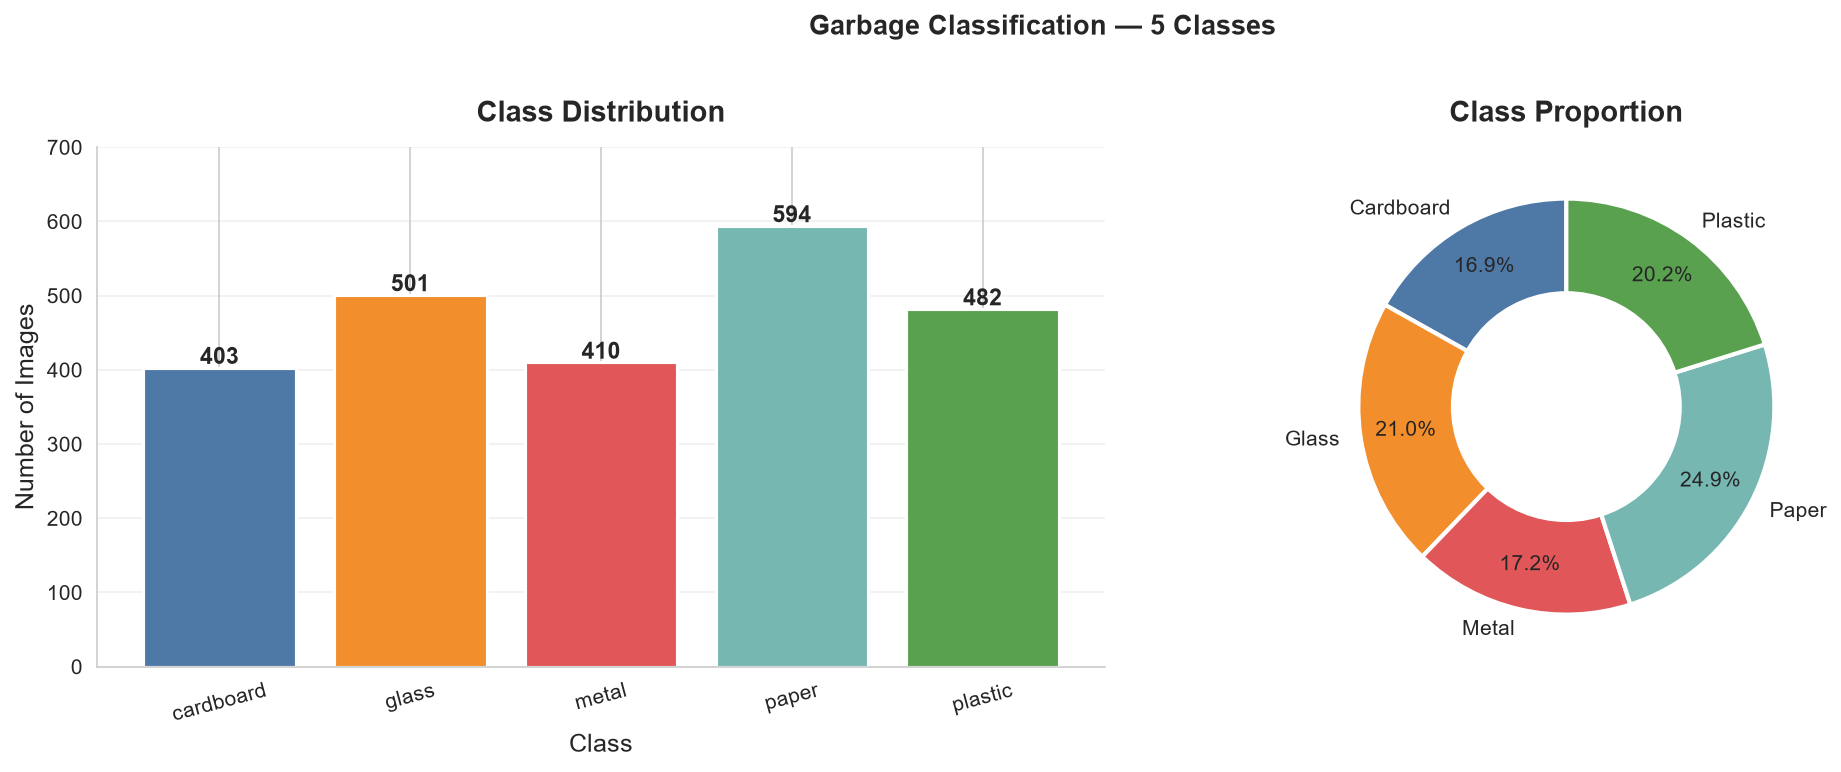

In [5]:
# ─── Class distribution bar chart ────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
bars = ax1.bar(class_counts.keys(), class_counts.values(),
               color=COLORS, edgecolor='white', linewidth=1.5)
for bar, cnt in zip(bars, class_counts.values()):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
             str(cnt), ha='center', fontweight='bold', fontsize=11)
ax1.set_title('Class Distribution', fontsize=14, fontweight='bold', pad=12)
ax1.set_xlabel('Class', fontsize=12)
ax1.set_ylabel('Number of Images', fontsize=12)
ax1.set_ylim(0, max(class_counts.values()) * 1.18)
ax1.grid(axis='y', alpha=0.3)
ax1.spines[['top', 'right']].set_visible(False)
ax1.tick_params(axis='x', rotation=15)

# Donut pie chart
wedges, texts, autotexts = ax2.pie(
    class_counts.values(),
    labels=[c.capitalize() for c in class_counts],
    autopct='%1.1f%%',
    colors=COLORS,
    startangle=90,
    pctdistance=0.78,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
ax2.add_artist(plt.Circle((0, 0), 0.55, fc='white'))
ax2.set_title('Class Proportion', fontsize=14, fontweight='bold', pad=12)

plt.suptitle('Garbage Classification — 5 Classes', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
dist_path = os.path.join(OUTPUT_DIR, 'mobilenetv2_class_distribution.png')
plt.savefig(dist_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: {dist_path}")

counts_arr = np.array(list(class_counts.values()))
ratio = counts_arr.max() / counts_arr.min()
print(f"\nImbalance ratio (max / min): {ratio:.2f}×")
if ratio > 3:
    print("⚠️  Significant imbalance detected — class weights will be applied.")
else:
    print("✅ Imbalance ratio acceptable (< 3×) — class weights will still be used.")


## 6. Train, Validation, and Test Splitting

Stratified splitting preserves class proportions in every subset.

| Split | Fraction | Purpose |
|-------|---------|---------|
| Training   | 70% | Gradient updates |
| Validation | 15% | Early stopping and model selection |
| Test       | 15% | Final, unbiased evaluation (used exactly once) |

Random seed = **42** ensures full reproducibility.


In [6]:
X = np.array(all_paths)
y = np.array(all_labels)

# Step 1: Reserve TEST_FRAC as test set
X_tv, X_test, y_tv, y_test = train_test_split(
    X, y, test_size=TEST_FRAC, stratify=y, random_state=RANDOM_SEED)

# Step 2: From remaining 85%, take val_frac_of_tv ≈ 17.65% as validation
val_frac_of_tv = VAL_FRAC / (TRAIN_FRAC + VAL_FRAC)
X_train, X_val, y_train, y_val = train_test_split(
    X_tv, y_tv, test_size=val_frac_of_tv, stratify=y_tv, random_state=RANDOM_SEED)

total = len(X)
print("Dataset split:")
print(f"  Training   : {len(X_train):>5}  ({100*len(X_train)/total:.1f}%)")
print(f"  Validation : {len(X_val):>5}  ({100*len(X_val)/total:.1f}%)")
print(f"  Test       : {len(X_test):>5}  ({100*len(X_test)/total:.1f}%)")
print(f"  Total      : {total:>5}  (100%)")

# Data leakage check
assert not (set(X_train) & set(X_val)),  "LEAKAGE: train ∩ val!"
assert not (set(X_train) & set(X_test)), "LEAKAGE: train ∩ test!"
assert not (set(X_val)   & set(X_test)), "LEAKAGE: val ∩ test!"
print("\n✅ No data leakage detected between any split pair.")

# Per-class counts across splits
print(f"\n  {'Class':<12}{'Train':>7}{'Val':>7}{'Test':>7}")
print("  " + "-" * 31)
for idx in range(NUM_CLASSES):
    cls = IDX_TO_CLASS[idx]
    t   = int((y_train == idx).sum())
    v   = int((y_val   == idx).sum())
    s   = int((y_test  == idx).sum())
    print(f"  {cls:<12}{t:>7}{v:>7}{s:>7}")


Dataset split:
  Training   :  1672  (70.0%)
  Validation :   359  (15.0%)
  Test       :   359  (15.0%)
  Total      :  2390  (100%)

✅ No data leakage detected between any split pair.

  Class         Train    Val   Test
  -------------------------------
  cardboard       282     60     61
  glass           351     75     75
  metal           286     62     62
  paper           416     89     89
  plastic         337     73     72


## 7. Data Augmentation

Data augmentation artificially expands training diversity by applying random,
label-preserving transformations. This reduces overfitting and improves generalization.

**Augmentation is applied to the training set only** — validation and test images are
only resized, centre-cropped, and normalized.

| Transform | Setting | Rationale |
|-----------|---------|-----------|
| RandomResizedCrop | 224 px, scale 0.8–1.0 | Simulates zoom and distance variation |
| RandomHorizontalFlip | p = 0.5 | Garbage items can appear flipped |
| RandomRotation | ±15° | Camera angle variation in real-world photos |
| ColorJitter | brightness/contrast ±0.2 | Lighting differences across environments |
| Normalize | ImageNet mean/std | Required to match MobileNetV2 pretraining |


In [7]:
# ─── Robust Tensor Transform (NumPy C-API independent) ────────────────────────
class RobustToTensor:
    """Converts a PIL Image or ndarray to a FloatTensor in [0.0, 1.0].
    Directly uses PyTorch's native memory buffers without calling torch.from_numpy(),
    ensuring 100% compatibility across Python 3.11/3.13 environments and preventing
    'RuntimeError: Numpy is not available'.
    """
    def __call__(self, pic):
        if hasattr(pic, 'convert'):
            return torchvision.transforms.functional.pil_to_tensor(pic).float().div(255.0)
        return torchvision.transforms.functional.to_tensor(pic)
    
    def __repr__(self):
        return "RobustToTensor()"

train_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.03),
    RobustToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    RobustToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print("Training transform pipeline:")
for t in train_tf.transforms:
    print(f"  {type(t).__name__}")
print("\nValidation / Test transform pipeline:")
for t in eval_tf.transforms:
    print(f"  {type(t).__name__}")


Training transform pipeline:
  Resize
  RandomResizedCrop
  RandomHorizontalFlip
  RandomRotation
  ColorJitter
  RobustToTensor
  Normalize

Validation / Test transform pipeline:
  Resize
  CenterCrop
  RobustToTensor
  Normalize


In [8]:
class GarbageDataset(Dataset):
    """Custom PyTorch Dataset for garbage image classification."""

    def __init__(self, paths, labels, transform=None):
        self.paths     = paths
        self.labels    = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img   = Image.open(self.paths[idx]).convert('RGB')
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label


# ─── Instantiate datasets ─────────────────────────────────────
train_ds = GarbageDataset(X_train, y_train, transform=train_tf)
val_ds   = GarbageDataset(X_val,   y_val,   transform=eval_tf)
test_ds  = GarbageDataset(X_test,  y_test,  transform=eval_tf)

# ─── DataLoaders (num_workers=0 for Windows / Python 3.13 compat) ─
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Sanity check
imgs_b, lbls_b = next(iter(train_dl))
print(f"Batch shape — images : {imgs_b.shape}  (B, C, H, W)")
print(f"Batch shape — labels : {lbls_b.shape}")
print(f"Image dtype          : {imgs_b.dtype}")
print(f"Pixel range (approx) : [{imgs_b.min():.2f}, {imgs_b.max():.2f}]")
print(f"\nTrain batches : {len(train_dl)} × {BATCH_SIZE}")
print(f"Val   batches : {len(val_dl)}")
print(f"Test  batches : {len(test_dl)}")


Batch shape — images : torch.Size([32, 3, 224, 224])  (B, C, H, W)
Batch shape — labels : torch.Size([32])
Image dtype          : torch.float32
Pixel range (approx) : [-2.12, 2.64]

Train batches : 53 × 32
Val   batches : 12
Test  batches : 12


✅ Saved: c:\Users\Asus\Downloads\viskom\outputs\mobilenetv2_sample_images.png


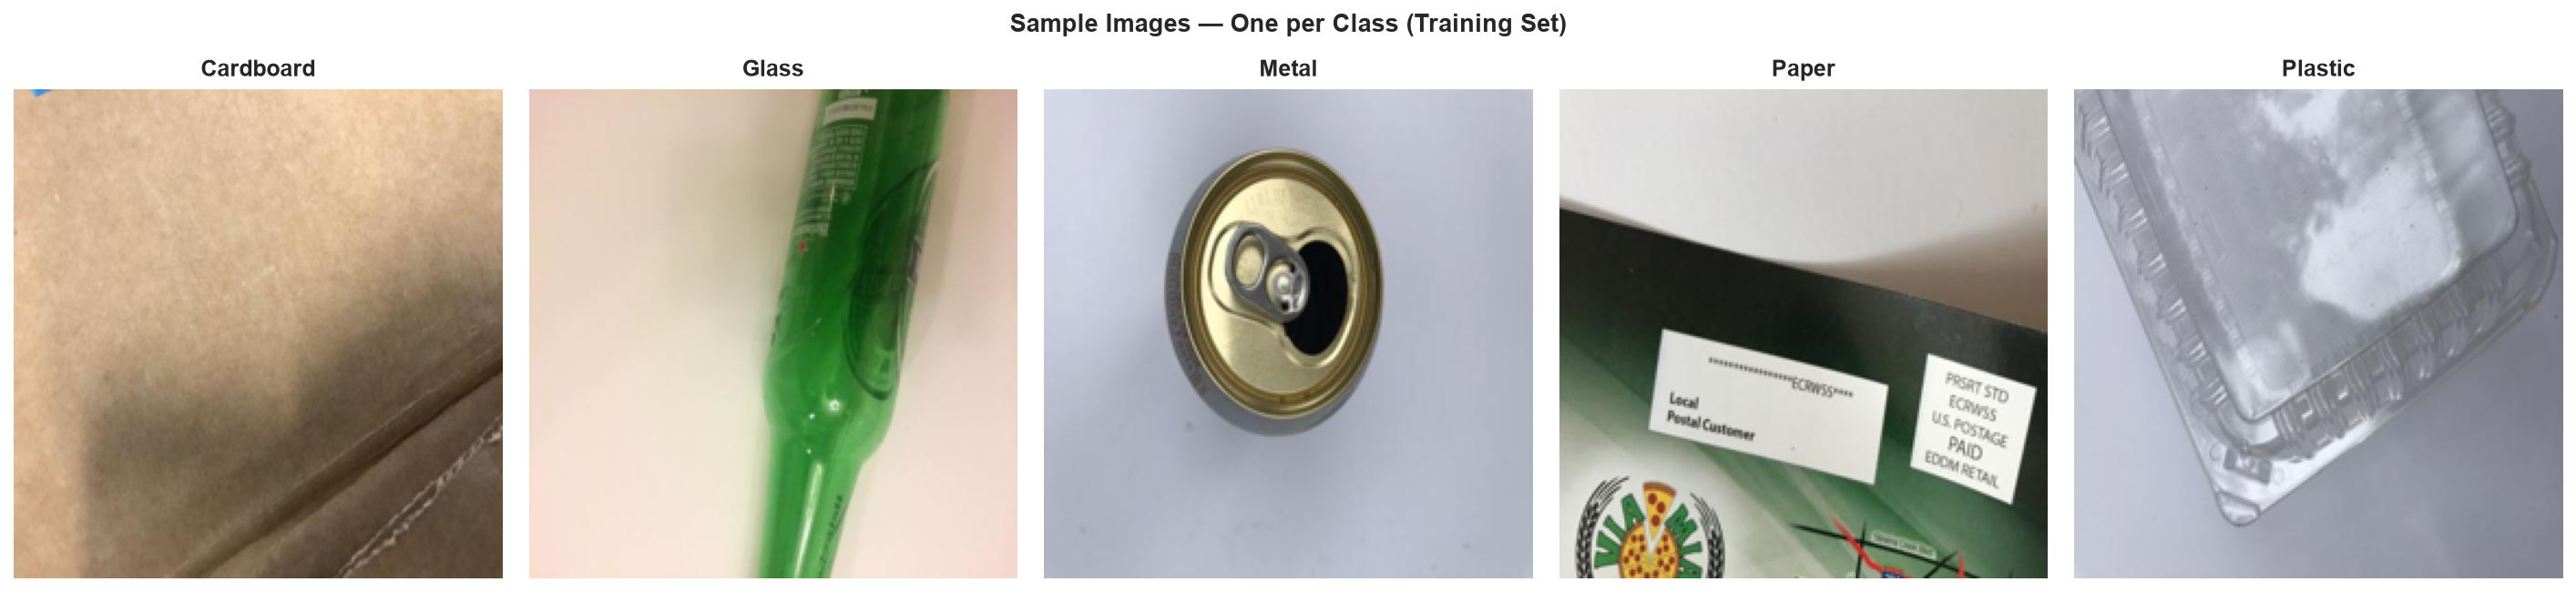

In [9]:
# ─── Sample images — one per class (from training set) ────────────────────────
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(3.8 * NUM_CLASSES, 4.2))
fig.suptitle('Sample Images — One per Class (Training Set)',
             fontsize=13, fontweight='bold', y=1.02)

for ci, cls in enumerate(CLASSES):
    mask = np.where(y_train == ci)[0]
    img  = Image.open(X_train[mask[0]]).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    axes[ci].imshow(img)
    axes[ci].set_title(cls.capitalize(), fontsize=12, fontweight='bold', pad=7)
    axes[ci].axis('off')
    for spine in axes[ci].spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(COLORS[ci])
        spine.set_linewidth(4)

plt.tight_layout()
samples_path = os.path.join(OUTPUT_DIR, 'mobilenetv2_sample_images.png')
plt.savefig(samples_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: {samples_path}")


## 8. MobileNetV2 Architecture and Transfer Learning

### Overview
MobileNetV2 (Sandler et al., 2018) is a convolutional neural network architecture engineered
for mobile and resource-constrained devices. It achieves competitive ImageNet accuracy at
significantly lower computational cost than standard architectures such as VGG-16 or ResNet-50.

---

### 1. Depthwise Separable Convolutions
Standard convolution mixes spatial and channel information simultaneously at cost
**k² · Cᵢₙ · Cₒᵤₜ**. MobileNetV2 decomposes this into:

- **Depthwise convolution (3×3):** One filter per input channel — captures spatial features independently.
- **Pointwise convolution (1×1):** Mixes information across channels.

Computational saving ≈ **1/9 + 1/Cₒᵤₜ** of standard convolution for k = 3 (roughly 8–9× fewer multiply-adds).

---

### 2. Inverted Residual Blocks (Linear Bottlenecks)
The central building block of MobileNetV2:

```
Input (narrow)  ──► [1×1 Expand  | ReLU6]  ──► [3×3 Depthwise | ReLU6]  ──► [1×1 Project | Linear]  ──► Output (narrow)
        └─────────────────────────────────── skip connection (if stride = 1) ──────────────────────────────────────────────┘
```

- **Expand:** A 1×1 conv expands channels by expansion factor *t* (default t = 6). Unlike ResNet
  bottlenecks, MobileNetV2 expands *before* depthwise filtering — hence "inverted".
- **Depthwise:** A 3×3 depthwise conv operates in the high-dimensional expanded space.
- **Project (Linear Bottleneck):** A 1×1 conv compresses back to a narrow representation using
  a **linear activation** (no ReLU). This is critical: applying ReLU to a low-dimensional
  representation destroys information (manifold collapse). The linear projection preserves it.

---

### 3. Architecture Summary

| Stage | Operator | Stride | Channels | Blocks |
|-------|----------|:------:|:--------:|:------:|
| 0 | Conv2d 3×3 | 2 | 32 | 1 |
| 1 | InvResidual t=1 | 1 | 16 | 1 |
| 2 | InvResidual t=6 | 2 | 24 | 2 |
| 3 | InvResidual t=6 | 2 | 32 | 3 |
| 4 | InvResidual t=6 | 2 | 64 | 4 |
| 5 | InvResidual t=6 | 1 | 96 | 3 |
| 6 | InvResidual t=6 | 2 | 160 | 3 |
| 7 | InvResidual t=6 | 1 | 320 | 1 |
| 8 | Conv2d 1×1 | 1 | 1280 | 1 |
| 9 | Global AvgPool + FC | — | 1000 | 1 |

**Total: ~3.4 M parameters.** For this task the FC head is replaced with a 5-class output.

---

### 4. Transfer Learning Strategy

| Phase | Backbone | Trained layers | Learning rate |
|-------|---------|---------------|--------------|
| Phase 1 | Fully frozen | Classifier head only | 1 × 10⁻³ |
| Phase 2 | features[14:] unfrozen | Upper backbone + classifier | 1 × 10⁻⁴ |

**Phase 1** establishes a strong baseline quickly by leveraging pretrained features.
**Phase 2** fine-tunes high-level features to adapt to garbage-specific visual patterns.

---

### 5. Advantages and Limitations for Garbage Classification

| | Details |
|-|---------|
| ✅ Advantages | ~3.4M parameters — compact and fast |
| ✅ Advantages | Inverted residuals allow efficient multi-scale feature reuse |
| ✅ Advantages | ImageNet features (edges, textures) transfer well to recyclable materials |
| ✅ Advantages | Suitable for edge/mobile deployment without GPU |
| ⚠️ Limitations | Linear bottleneck limits expressiveness in low-dimensional projections |
| ⚠️ Limitations | May underperform larger models on visually similar classes (e.g., cardboard vs. paper) |


## 8a. Building the Transfer Learning Model

In [10]:
# ─── Load pretrained MobileNetV2 ─────────────────────────────────────────────
try:
    from torchvision.models import MobileNet_V2_Weights
    model = models.mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1)
    print("✅ Loaded MobileNetV2 — new API (MobileNet_V2_Weights.IMAGENET1K_V1)")
except (ImportError, AttributeError):
    model = models.mobilenet_v2(pretrained=True)
    print("✅ Loaded MobileNetV2 — legacy API (pretrained=True)")

# ─── Phase 1: freeze entire backbone ─────────────────────────────────────────
for param in model.features.parameters():
    param.requires_grad = False

# ─── Replace classifier head ──────────────────────────────────────────────────
#  Original : Sequential(Dropout(0.2), Linear(1280, 1000))
#  New      : Sequential(Dropout(0.3), Linear(1280, NUM_CLASSES))
in_feats = model.last_channel   # 1280

model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_feats, NUM_CLASSES)
)
model = model.to(DEVICE)

# ─── Parameter summary ───────────────────────────────────────────────────────
total_p  = sum(p.numel() for p in model.parameters())
train_p  = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_p = total_p - train_p

print(f"\nClassifier head : {model.classifier}")
print(f"\nParameter counts (Phase 1):")
print(f"  Total            : {total_p:>10,}")
print(f"  Trainable (head) : {train_p:>10,}")
print(f"  Frozen (backbone): {frozen_p:>10,}")


✅ Loaded MobileNetV2 — new API (MobileNet_V2_Weights.IMAGENET1K_V1)

Classifier head : Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=5, bias=True)
)

Parameter counts (Phase 1):
  Total            :  2,230,277
  Trainable (head) :      6,405
  Frozen (backbone):  2,223,872


## 9. Model Compilation — Loss, Optimizer, and Scheduler

- **Loss:** `CrossEntropyLoss` with per-class weights computed from training distribution.
  Class weights penalize misclassification of minority classes more heavily.
- **Optimizer:** `Adam` — adaptive per-parameter learning rates; efficient convergence.
- **Scheduler:** `ReduceLROnPlateau` — halves the learning rate when validation loss plateaus.


In [11]:
# ─── Class weights ────────────────────────────────────────────────────────────
cw_vals   = compute_class_weight('balanced',
                                  classes=np.arange(NUM_CLASSES),
                                  y=y_train)
cw_tensor = torch.tensor(cw_vals, dtype=torch.float32).to(DEVICE)

print("Class weights:")
for cls, w in zip(CLASSES, cw_vals):
    print(f"  {cls:<12} : {w:.4f}")

criterion = nn.CrossEntropyLoss(weight=cw_tensor)

# ─── Phase 1 optimizer (head only) ───────────────────────────────────────────
opt_p1 = optim.Adam(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR_P1, weight_decay=WEIGHT_DECAY
)
sch_p1 = optim.lr_scheduler.ReduceLROnPlateau(
    opt_p1, mode='min', factor=0.5, patience=3
)

print(f"\nLoss      : CrossEntropyLoss (weighted)")
print(f"Optimizer : Adam  (lr={LR_P1}, weight_decay={WEIGHT_DECAY})")
print(f"Scheduler : ReduceLROnPlateau (factor=0.5, patience=3)")


Class weights:
  cardboard    : 1.1858
  glass        : 0.9527
  metal        : 1.1692
  paper        : 0.8038
  plastic      : 0.9923

Loss      : CrossEntropyLoss (weighted)
Optimizer : Adam  (lr=0.001, weight_decay=0.0001)
Scheduler : ReduceLROnPlateau (factor=0.5, patience=3)


## 10. Training and Validation

### Training Loop
Each epoch performs:
1. Forward pass → compute cross-entropy loss → backward pass → optimizer step (training).
2. Forward pass (no grad) → compute validation loss and accuracy.
3. Scheduler steps on validation loss.
4. Best checkpoint saved when validation accuracy improves.
5. Early stopping halts training after `EARLY_STOP_PAT` consecutive non-improving epochs.


In [12]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for imgs, lbls in loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss   = criterion(logits, lbls)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits.argmax(1) == lbls).sum().item()
        n          += imgs.size(0)
    return total_loss / n, 100.0 * correct / n


@torch.no_grad()
def eval_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for imgs, lbls in loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        logits = model(imgs)
        loss   = criterion(logits, lbls)
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits.argmax(1) == lbls).sum().item()
        n          += imgs.size(0)
    return total_loss / n, 100.0 * correct / n


def train_model(model, tr_dl, va_dl, criterion, optimizer, scheduler,
                n_epochs, ckpt_path, phase, device,
                patience=EARLY_STOP_PAT):
    hist = {'tr_loss': [], 'va_loss': [],
            'tr_acc':  [], 'va_acc':  [], 'lr': []}
    best_va_acc = 0.0
    pat_ctr     = 0
    t0          = time.time()

    print(f"\n{'='*66}")
    print(f"  {phase}")
    print(f"{'='*66}")
    hdr = (f"  {'Epoch':>5}  {'TrLoss':>8}  {'TrAcc':>7}  "
           f"{'VaLoss':>8}  {'VaAcc':>7}  {'LR':>9}  Status")
    print(hdr)
    print("  " + "-"*63)

    for ep in range(1, n_epochs + 1):
        tr_loss, tr_acc = train_epoch(model, tr_dl, criterion, optimizer, device)
        va_loss, va_acc = eval_epoch(model, va_dl, criterion, device)
        cur_lr = optimizer.param_groups[0]['lr']
        scheduler.step(va_loss)

        hist['tr_loss'].append(tr_loss)
        hist['va_loss'].append(va_loss)
        hist['tr_acc'].append(tr_acc)
        hist['va_acc'].append(va_acc)
        hist['lr'].append(cur_lr)

        status = ''
        if va_acc > best_va_acc:
            best_va_acc = va_acc
            pat_ctr = 0
            torch.save(model.state_dict(), ckpt_path)
            status = '✅ BEST'
        else:
            pat_ctr += 1
            if pat_ctr >= patience:
                status = '⏹ STOP'

        print(f"  {ep:>5}  {tr_loss:>8.4f}  {tr_acc:>6.2f}%  "
              f"{va_loss:>8.4f}  {va_acc:>6.2f}%  {cur_lr:>9.2e}  {status}")

        if '⏹' in status:
            print(f"\n  Early stopping triggered at epoch {ep}.")
            break

    elapsed = time.time() - t0
    print(f"\n  Best Val Acc : {best_va_acc:.2f}%")
    print(f"  Training time: {elapsed:.0f}s ({elapsed/60:.1f} min)")
    return hist, elapsed, best_va_acc


print("Training helper functions defined successfully.")


Training helper functions defined successfully.


## 10a. Phase 1 — Training the Classification Head (Frozen Backbone)

In [13]:
print(f"Phase 1 trainable parameters: "
      f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

hist_p1, time_p1, best_acc_p1 = train_model(
    model, train_dl, val_dl,
    criterion, opt_p1, sch_p1,
    n_epochs  = NUM_EPOCHS_P1,
    ckpt_path = CKPT_P1,
    phase     = "PHASE 1 — Frozen Backbone (Head Only)",
    device    = DEVICE
)
print(f"\n✅ Phase 1 best checkpoint saved: {CKPT_P1}")


Phase 1 trainable parameters: 6,405

  PHASE 1 — Frozen Backbone (Head Only)
  Epoch    TrLoss    TrAcc    VaLoss    VaAcc         LR  Status
  ---------------------------------------------------------------
      1    1.1295   55.20%    0.7540   77.16%   1.00e-03  ✅ BEST
      2    0.7475   72.25%    0.5725   80.22%   1.00e-03  ✅ BEST
      3    0.6565   76.20%    0.5013   84.12%   1.00e-03  ✅ BEST
      4    0.5941   78.71%    0.4836   85.79%   1.00e-03  ✅ BEST
      5    0.5618   79.67%    0.4490   84.68%   1.00e-03  
      6    0.5335   79.55%    0.4788   82.17%   1.00e-03  
      7    0.5145   80.74%    0.4235   85.52%   1.00e-03  
      8    0.5033   81.46%    0.4184   85.52%   1.00e-03  
      9    0.4962   81.88%    0.4569   83.29%   1.00e-03  ⏹ STOP

  Early stopping triggered at epoch 9.

  Best Val Acc : 85.79%
  Training time: 589s (9.8 min)

✅ Phase 1 best checkpoint saved: c:\Users\Asus\Downloads\viskom\outputs\ckpt_phase1_best.pth


## 11. Phase 2 — Fine-Tuning (Upper Backbone Layers)

We unfreeze **`features[14:]`** (the last four inverted residual blocks and the final conv layer)
and continue training at a very low learning rate (1 × 10⁻⁴) to avoid catastrophic forgetting
of the pretrained ImageNet features.

**Rationale:** Garbage textures (crinkled paper, transparent plastic, metallic sheen) differ
from typical ImageNet content. Adapting the upper backbone layers allows the model to learn
domain-specific high-level features that cannot be captured by the classification head alone.

> If Phase 2 does not improve validation accuracy, the Phase 1 checkpoint is used as the final model.


In [14]:
# ─── Load best Phase 1 weights ───────────────────────────────────────────────
model.load_state_dict(torch.load(CKPT_P1, map_location=DEVICE))
print(f"Loaded Phase 1 best checkpoint: {CKPT_P1}")

# ─── Unfreeze features[14:] + classifier ─────────────────────────────────────
UNFREEZE_FROM = 14
for i, layer in enumerate(model.features):
    for param in layer.parameters():
        param.requires_grad = (i >= UNFREEZE_FROM)
for param in model.classifier.parameters():
    param.requires_grad = True

p2_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nUnfreezing features[{UNFREEZE_FROM}:] + classifier")
print(f"Phase 2 trainable parameters: {p2_trainable:,}")

# ─── Phase 2 optimizer and scheduler ─────────────────────────────────────────
opt_p2 = optim.Adam(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR_P2, weight_decay=WEIGHT_DECAY
)
sch_p2 = optim.lr_scheduler.ReduceLROnPlateau(
    opt_p2, mode='min', factor=0.5, patience=3
)

hist_p2, time_p2, best_acc_p2 = train_model(
    model, train_dl, val_dl,
    criterion, opt_p2, sch_p2,
    n_epochs  = NUM_EPOCHS_P2,
    ckpt_path = CKPT_P2,
    phase     = "PHASE 2 — Fine-Tuning (features[14:] + classifier)",
    device    = DEVICE
)

# ─── Select best checkpoint ───────────────────────────────────────────────────
if best_acc_p2 > best_acc_p1:
    BEST_CKPT = CKPT_P2
    print(f"\n✅ Phase 2 improved val accuracy → best checkpoint: {CKPT_P2}")
else:
    BEST_CKPT = CKPT_P1
    print(f"\nℹ️  Phase 1 was better or equal → best checkpoint: {CKPT_P1}")

print(f"\nPhase 1 best val acc : {best_acc_p1:.2f}%")
print(f"Phase 2 best val acc : {best_acc_p2:.2f}%")
print(f"Selected             : {BEST_CKPT}")


Loaded Phase 1 best checkpoint: c:\Users\Asus\Downloads\viskom\outputs\ckpt_phase1_best.pth

Unfreezing features[14:] + classifier
Phase 2 trainable parameters: 1,687,749

  PHASE 2 — Fine-Tuning (features[14:] + classifier)
  Epoch    TrLoss    TrAcc    VaLoss    VaAcc         LR  Status
  ---------------------------------------------------------------
      1    0.4680   82.95%    0.3291   88.02%   1.00e-04  ✅ BEST
      2    0.3102   89.11%    0.2681   90.81%   1.00e-04  ✅ BEST
      3    0.2327   92.58%    0.2271   92.76%   1.00e-04  ✅ BEST
      4    0.1811   94.02%    0.2347   91.64%   1.00e-04  
      5    0.1534   94.44%    0.2141   92.76%   1.00e-04  
      6    0.1168   95.63%    0.2004   93.04%   1.00e-04  ✅ BEST
      7    0.0912   96.65%    0.1830   93.31%   1.00e-04  ✅ BEST
      8    0.0762   97.85%    0.2068   92.48%   1.00e-04  
      9    0.0835   97.43%    0.1991   94.15%   1.00e-04  ✅ BEST
     10    0.0907   96.71%    0.2474   93.04%   1.00e-04  

  Best Val Acc : 

## 12. Test-Set Evaluation

The best model checkpoint is evaluated **exactly once** on the held-out test set.
The test set was never used for model selection or hyperparameter tuning.

> ⚠️ Do not adjust hyperparameters based on test results — this would invalidate the evaluation.


In [15]:
# ─── Load best checkpoint ────────────────────────────────────────────────────
model.load_state_dict(torch.load(BEST_CKPT, map_location=DEVICE))
model.eval()
print(f"Evaluating checkpoint: {BEST_CKPT}\n")

# ─── Inference over test set ──────────────────────────────────────────────────
all_preds = []
all_true  = []
all_probs = []

with torch.no_grad():
    for imgs, lbls in test_dl:
        imgs  = imgs.to(DEVICE)
        out   = model(imgs)
        probs = torch.softmax(out, dim=1)
        all_preds.extend(probs.argmax(1).cpu().numpy())
        all_true.extend(lbls.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_true  = np.array(all_true)
all_probs = np.array(all_probs)

test_acc = accuracy_score(all_true, all_preds) * 100
print(f"Test samples  : {len(all_true)}")
print(f"Test Accuracy : {test_acc:.2f}%")


Evaluating checkpoint: c:\Users\Asus\Downloads\viskom\outputs\ckpt_phase2_best.pth

Test samples  : 359
Test Accuracy : 92.76%


## 13. Classification Report and Confusion Matrix

In [16]:
cls_labels = [c.capitalize() for c in CLASSES]

report_str = classification_report(
    all_true, all_preds, target_names=cls_labels, digits=4)

print("=" * 64)
print("CLASSIFICATION REPORT — TEST SET")
print("=" * 64)
print(report_str)

rpt_path = os.path.join(OUTPUT_DIR, 'mobilenetv2_classification_report.txt')
with open(rpt_path, 'w', encoding='utf-8') as f:
    f.write("MobileNetV2 Garbage Classification — Test Set\n")
    f.write("=" * 64 + "\n")
    f.write(f"Best checkpoint : {BEST_CKPT}\n\n")
    f.write(report_str)
print(f"✅ Saved: {rpt_path}")

# ─── Aggregate metrics ────────────────────────────────────────────────────────
precision, recall, f1, support = precision_recall_fscore_support(
    all_true, all_preds, average=None, labels=np.arange(NUM_CLASSES))
macro_p,   macro_r,   macro_f1,   _ = precision_recall_fscore_support(
    all_true, all_preds, average='macro')
weight_p,  weight_r,  weight_f1,  _ = precision_recall_fscore_support(
    all_true, all_preds, average='weighted')

print("\nSummary metrics:")
print(f"  Test Accuracy       : {test_acc:.2f}%")
print(f"  Macro Precision     : {macro_p  *100:.2f}%")
print(f"  Macro Recall        : {macro_r  *100:.2f}%")
print(f"  Macro F1-Score      : {macro_f1 *100:.2f}%")
print(f"  Weighted Precision  : {weight_p *100:.2f}%")
print(f"  Weighted Recall     : {weight_r *100:.2f}%")
print(f"  Weighted F1-Score   : {weight_f1*100:.2f}%")


CLASSIFICATION REPORT — TEST SET
              precision    recall  f1-score   support

   Cardboard     0.9524    0.9836    0.9677        61
       Glass     0.9091    0.9333    0.9211        75
       Metal     0.8841    0.9839    0.9313        62
       Paper     0.9762    0.9213    0.9480        89
     Plastic     0.9091    0.8333    0.8696        72

    accuracy                         0.9276       359
   macro avg     0.9262    0.9311    0.9275       359
weighted avg     0.9288    0.9276    0.9271       359

✅ Saved: c:\Users\Asus\Downloads\viskom\outputs\mobilenetv2_classification_report.txt

Summary metrics:
  Test Accuracy       : 92.76%
  Macro Precision     : 92.62%
  Macro Recall        : 93.11%
  Macro F1-Score      : 92.75%
  Weighted Precision  : 92.88%
  Weighted Recall     : 92.76%
  Weighted F1-Score   : 92.71%


✅ Saved: c:\Users\Asus\Downloads\viskom\outputs\mobilenetv2_confusion_matrix.png


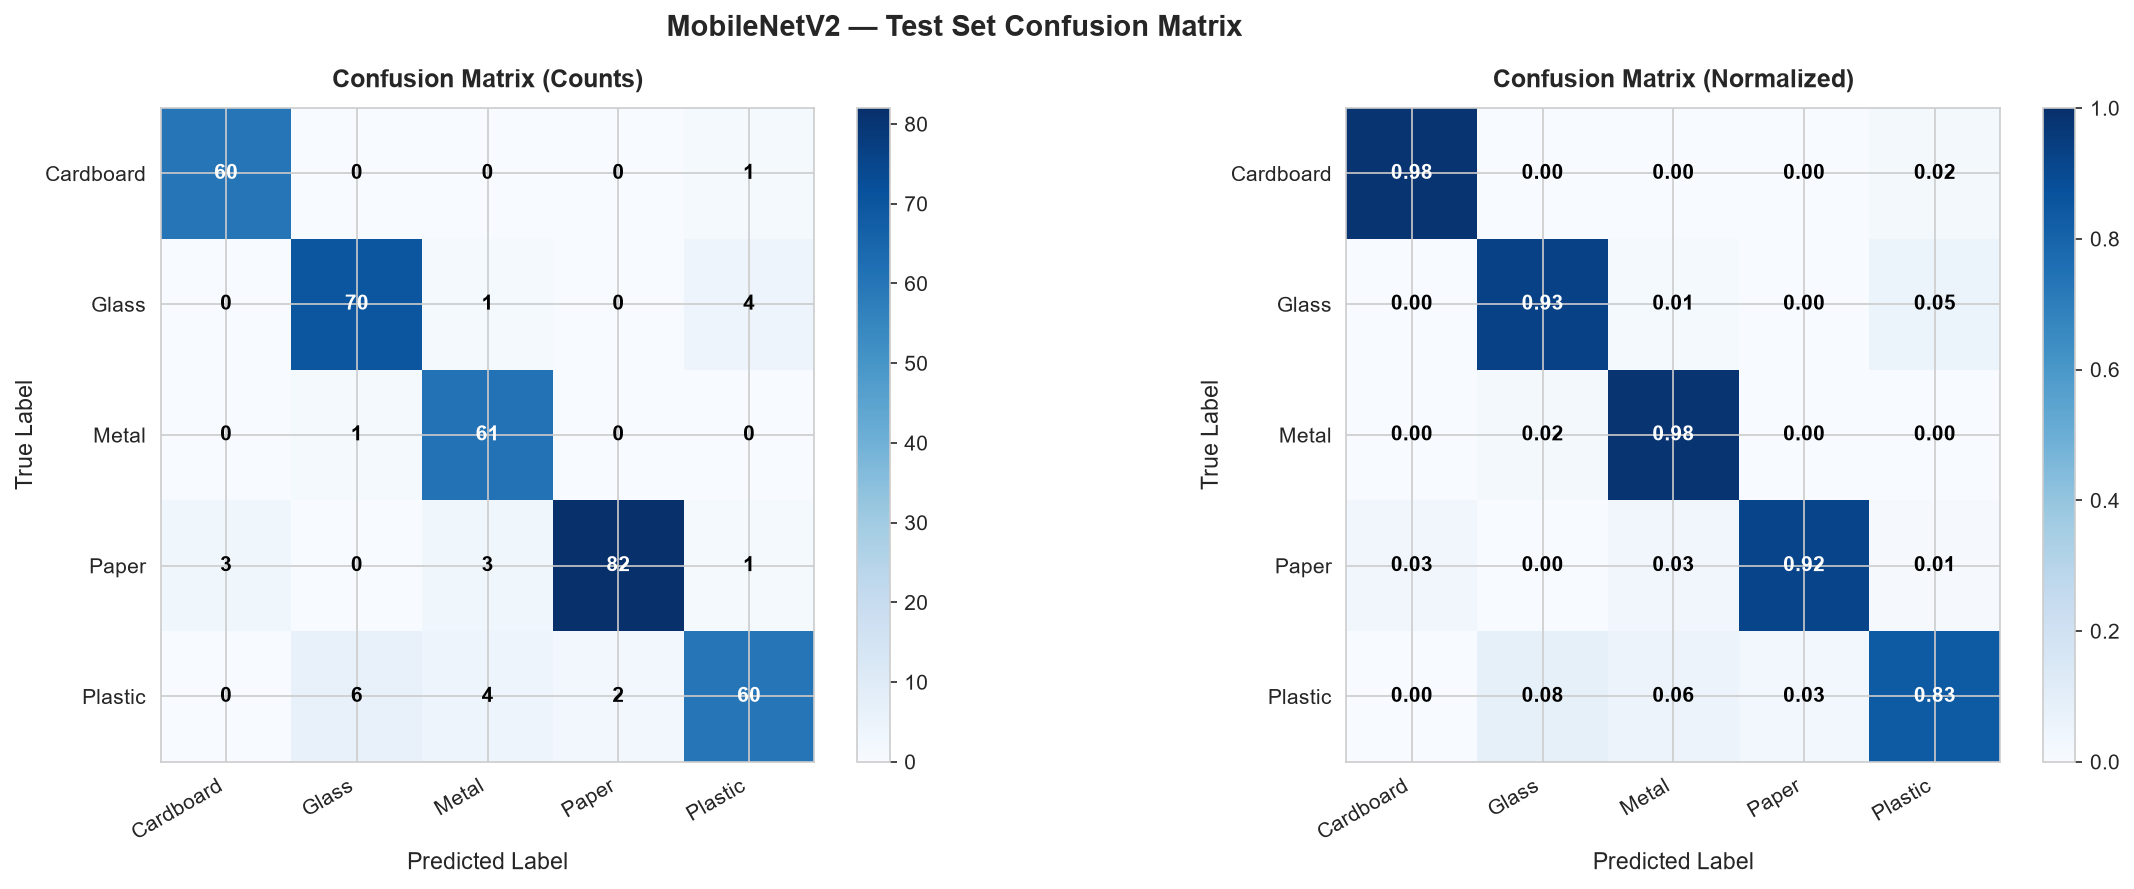

In [17]:
# ─── Confusion matrix (matplotlib imshow) ────────────────────────────────────
cm      = confusion_matrix(all_true, all_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, data, fmt, title in zip(
    axes,
    [cm, cm_norm],
    ['d', '.2f'],
    ['Confusion Matrix (Counts)', 'Confusion Matrix (Normalized)']
):
    im = ax.imshow(data, interpolation='nearest', cmap='Blues',
                   vmin=0, vmax=(1 if fmt == '.2f' else None))
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(cls_labels, rotation=30, ha='right', fontsize=10)
    ax.set_yticklabels(cls_labels, fontsize=10)
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('True Label',      fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    thresh = data.max() / 2.0
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            color = 'white' if data[i, j] > thresh else 'black'
            ax.text(j, i, format(data[i, j], fmt),
                    ha='center', va='center',
                    fontsize=10, fontweight='bold', color=color)

plt.suptitle('MobileNetV2 — Test Set Confusion Matrix',
             fontsize=14, fontweight='bold')
plt.tight_layout()
cm_path = os.path.join(OUTPUT_DIR, 'mobilenetv2_confusion_matrix.png')
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: {cm_path}")


✅ Saved: mobilenetv2_per_class_metrics.png


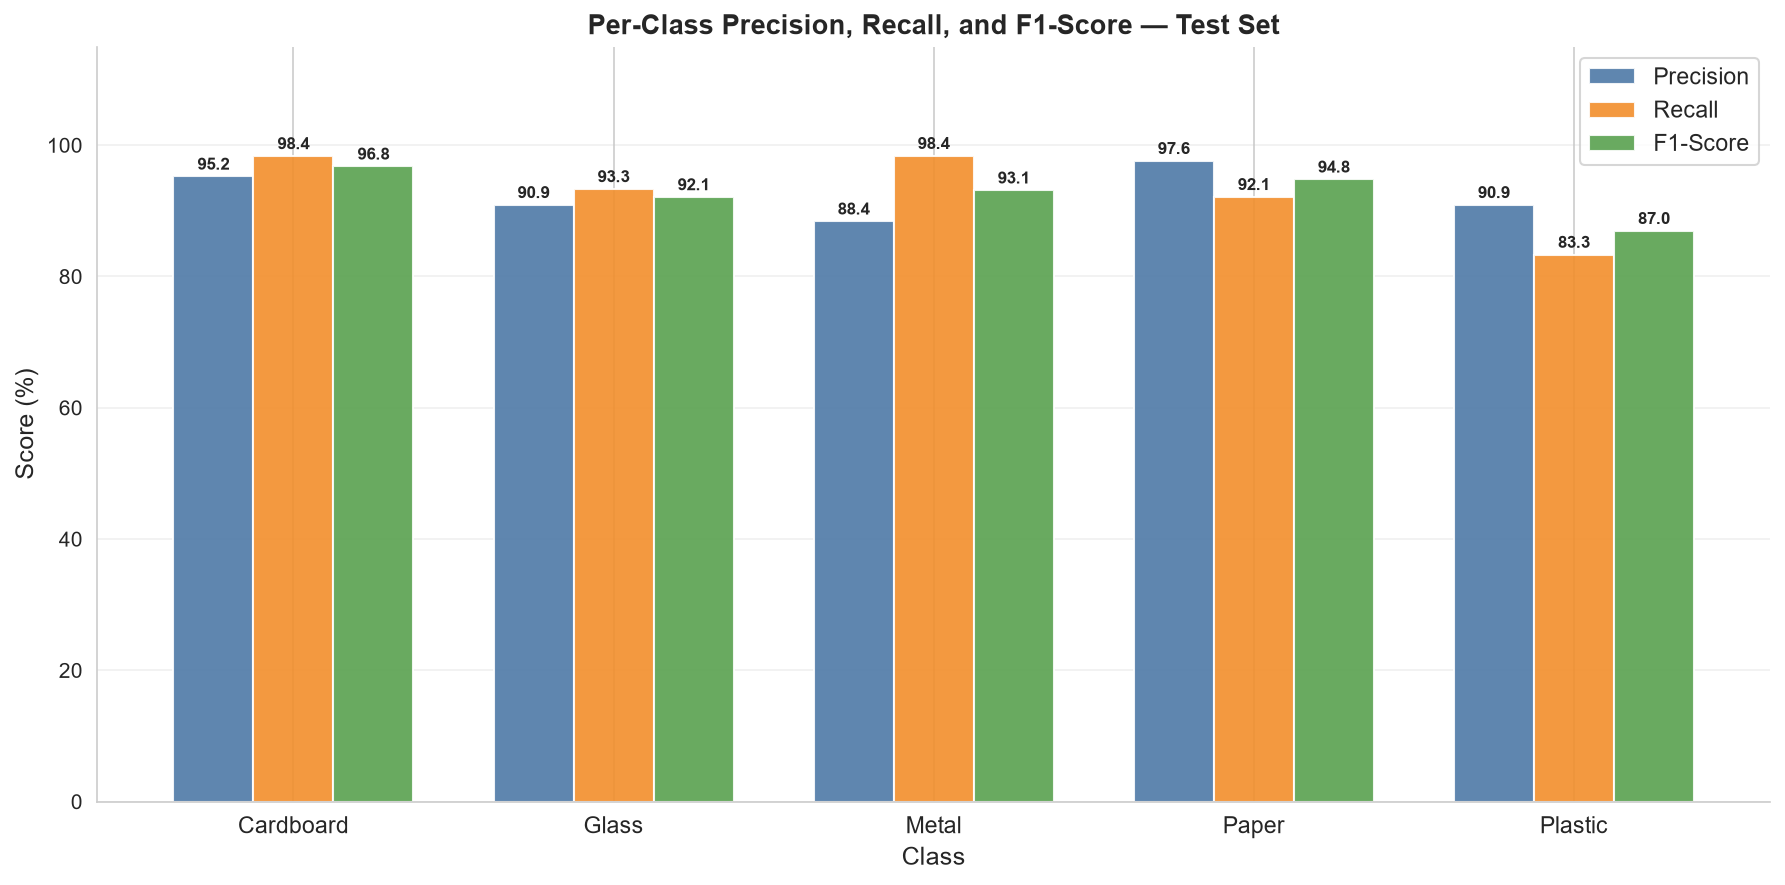

In [18]:
# ─── Per-class metrics bar chart ─────────────────────────────────────────────
x, w = np.arange(NUM_CLASSES), 0.25
fig, ax = plt.subplots(figsize=(12, 6))

for i, (metric, vals, color) in enumerate([
    ('Precision', precision, '#4E79A7'),
    ('Recall',    recall,    '#F28E2B'),
    ('F1-Score',  f1,        '#59A14F')
]):
    bars = ax.bar(x + (i-1)*w, vals*100, w,
                  label=metric, color=color, alpha=0.9, edgecolor='white')
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
                f'{h:.1f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(cls_labels, fontsize=11)
ax.set_xlabel('Class', fontsize=12)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Per-Class Precision, Recall, and F1-Score — Test Set',
             fontsize=13, fontweight='bold')
ax.set_ylim(0, 115)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'mobilenetv2_per_class_metrics.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: mobilenetv2_per_class_metrics.png")


## 14. Training Curve Visualization

✅ Saved: c:\Users\Asus\Downloads\viskom\outputs\mobilenetv2_training_curves.png


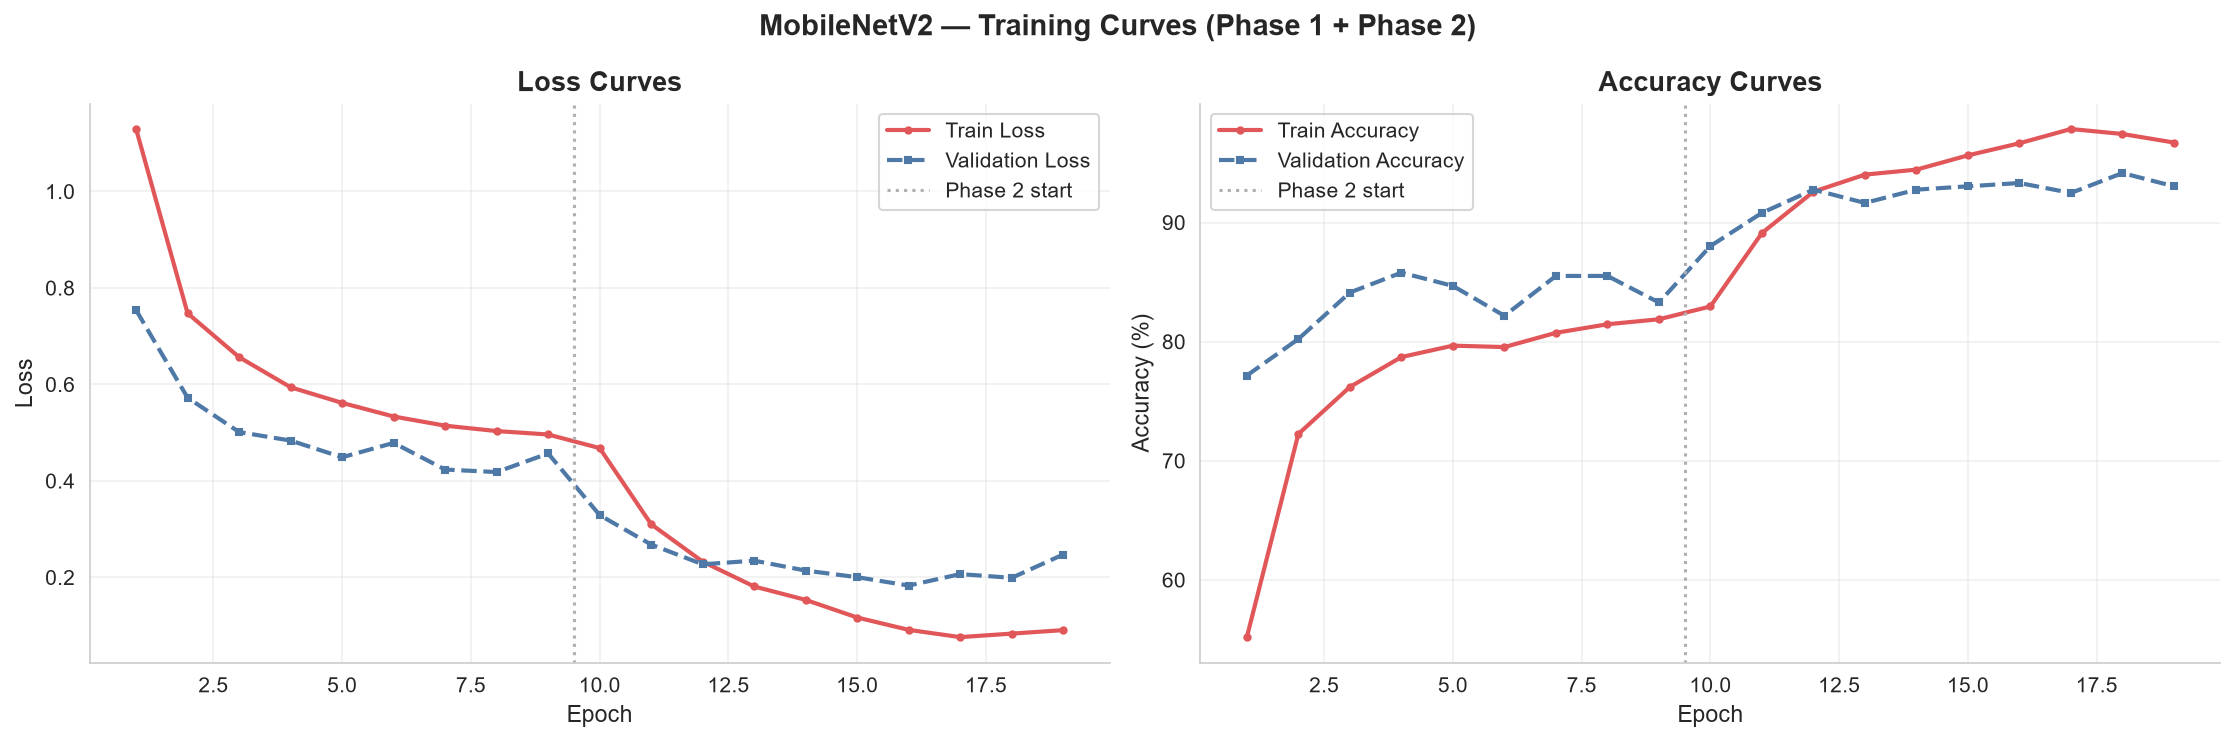

In [19]:
# ─── Combine Phase 1 + Phase 2 histories ─────────────────────────────────────
comb_tr_loss = hist_p1['tr_loss'] + hist_p2['tr_loss']
comb_va_loss = hist_p1['va_loss'] + hist_p2['va_loss']
comb_tr_acc  = hist_p1['tr_acc']  + hist_p2['tr_acc']
comb_va_acc  = hist_p1['va_acc']  + hist_p2['va_acc']
p1_end       = len(hist_p1['tr_loss'])
epochs_rng   = range(1, len(comb_tr_loss) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Loss
ax1.plot(epochs_rng, comb_tr_loss, '-o', color='#E15759',
         label='Train Loss',       ms=3, lw=2)
ax1.plot(epochs_rng, comb_va_loss, '--s', color='#4E79A7',
         label='Validation Loss',  ms=3, lw=2)
ax1.axvline(x=p1_end + 0.5, color='#B0B0B0', linestyle=':',
            lw=1.5, label='Phase 2 start')
ax1.set_title('Loss Curves',    fontsize=13, fontweight='bold')
ax1.set_xlabel('Epoch',         fontsize=11)
ax1.set_ylabel('Loss',          fontsize=11)
ax1.legend(fontsize=10)
ax1.grid(alpha=0.3)
ax1.spines[['top', 'right']].set_visible(False)

# Accuracy
ax2.plot(epochs_rng, comb_tr_acc, '-o', color='#E15759',
         label='Train Accuracy',      ms=3, lw=2)
ax2.plot(epochs_rng, comb_va_acc, '--s', color='#4E79A7',
         label='Validation Accuracy', ms=3, lw=2)
ax2.axvline(x=p1_end + 0.5, color='#B0B0B0', linestyle=':',
            lw=1.5, label='Phase 2 start')
ax2.set_title('Accuracy Curves', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epoch',          fontsize=11)
ax2.set_ylabel('Accuracy (%)',   fontsize=11)
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3)
ax2.spines[['top', 'right']].set_visible(False)

plt.suptitle('MobileNetV2 — Training Curves (Phase 1 + Phase 2)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
tc_path = os.path.join(OUTPUT_DIR, 'mobilenetv2_training_curves.png')
plt.savefig(tc_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: {tc_path}")


## 15. Prediction Visualization

✅ Saved: c:\Users\Asus\Downloads\viskom\outputs\mobilenetv2_predictions.png
  Correct   shown : 8
  Incorrect shown : 8


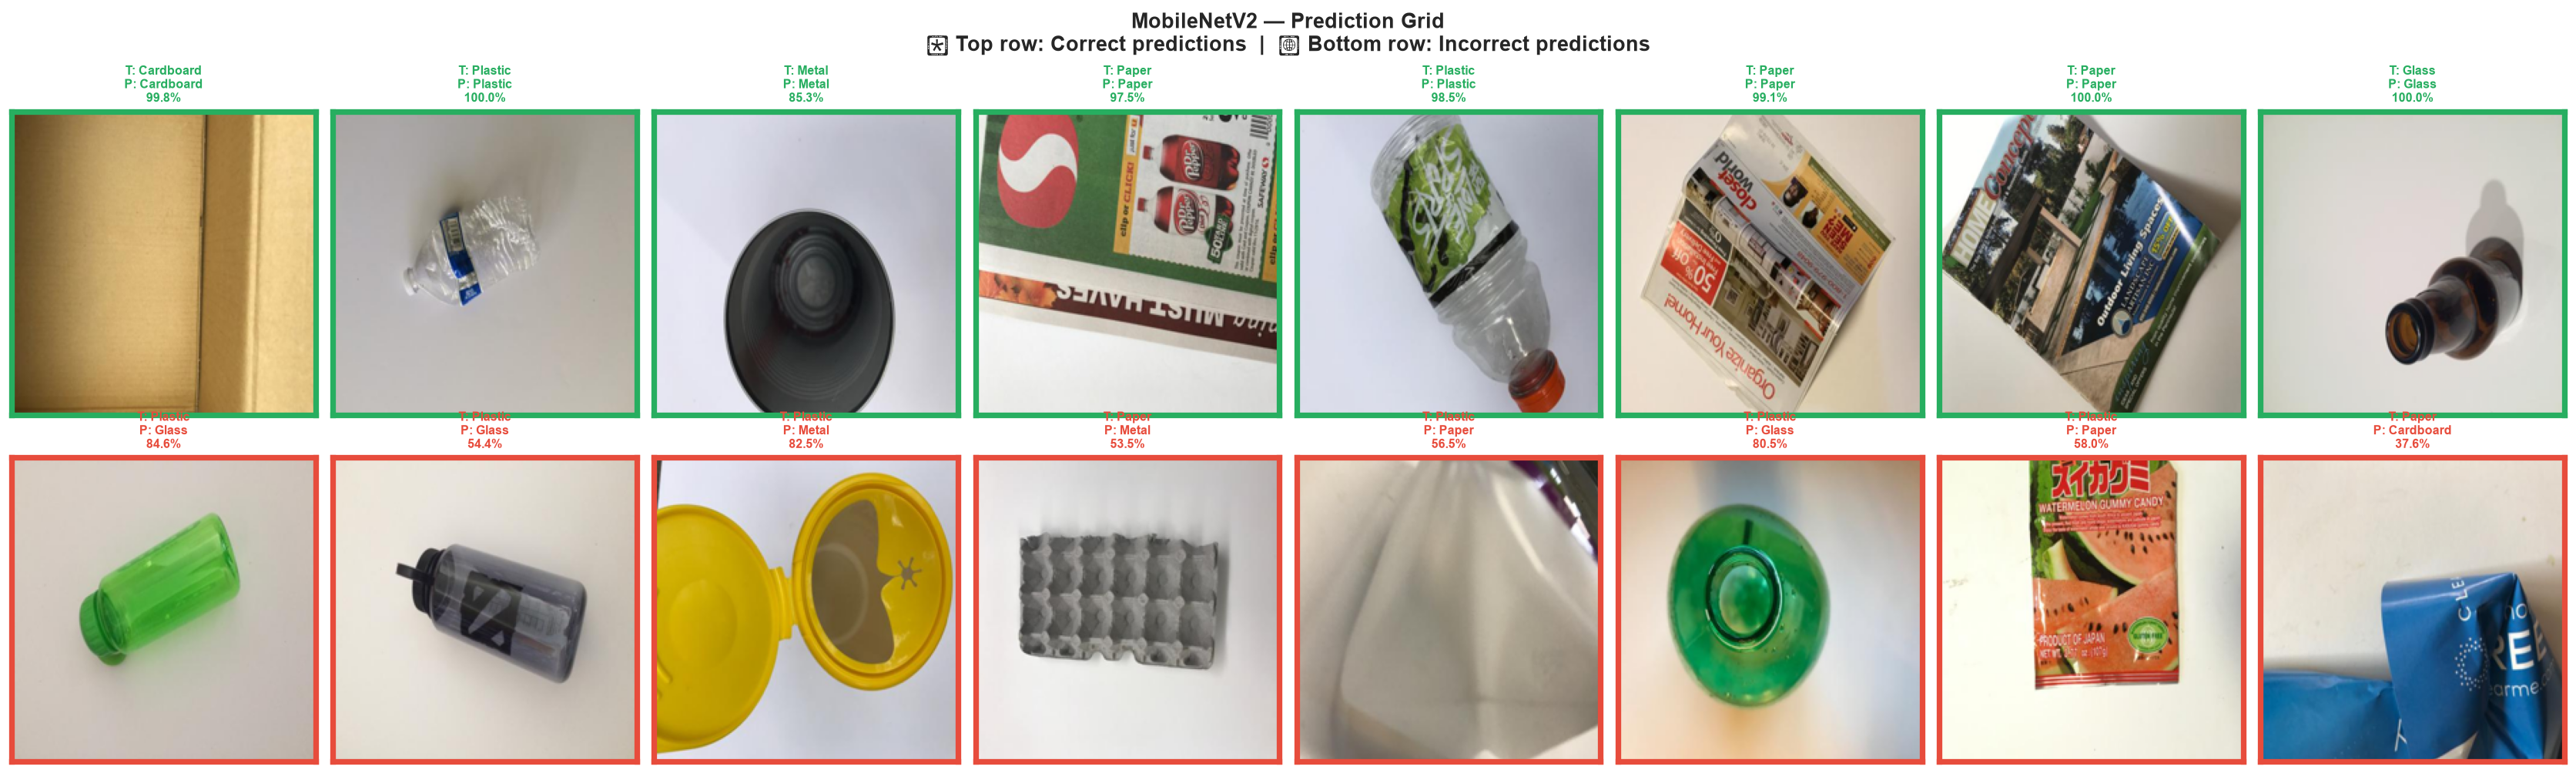

In [20]:
# ─── Separate correct and incorrect predictions ───────────────────────────────
conf_scores   = all_probs.max(axis=1)
correct_idx   = [i for i in range(len(all_preds)) if all_preds[i] == all_true[i]]
incorrect_idx = [i for i in range(len(all_preds)) if all_preds[i] != all_true[i]]

n_show = 8
c_idx  = correct_idx[:min(n_show, len(correct_idx))]
w_idx  = incorrect_idx[:min(n_show, len(incorrect_idx))]

fig, axes = plt.subplots(2, n_show, figsize=(2.8 * n_show, 7.0))
fig.suptitle(
    'MobileNetV2 — Prediction Grid\n'
    '🟢 Top row: Correct predictions  |  🔴 Bottom row: Incorrect predictions',
    fontsize=13, fontweight='bold'
)

row_configs = [
    (c_idx, '#27AE60'),
    (w_idx, '#E74C3C')
]

for row, (idxs, border_color) in enumerate(row_configs):
    for col in range(n_show):
        ax = axes[row][col]
        if col < len(idxs):
            idx      = idxs[col]
            img      = Image.open(X_test[idx]).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
            true_cls = CLASSES[all_true[idx]].capitalize()
            pred_cls = CLASSES[all_preds[idx]].capitalize()
            conf     = conf_scores[idx] * 100
            ax.imshow(img)
            ax.set_title(f"T: {true_cls}\nP: {pred_cls}\n{conf:.1f}%",
                         fontsize=7.5, color=border_color, fontweight='bold')
            for spine in ax.spines.values():
                spine.set_edgecolor(border_color)
                spine.set_linewidth(3.5)
        else:
            ax.axis('off')
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
pred_path = os.path.join(OUTPUT_DIR, 'mobilenetv2_predictions.png')
plt.savefig(pred_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: {pred_path}")
print(f"  Correct   shown : {len(c_idx)}")
print(f"  Incorrect shown : {len(w_idx)}")


## 16. Computational Efficiency Analysis

We measure:
1. **Total / trainable / frozen parameters**
2. **Saved model file size**
3. **Single-image inference latency** — 50 timed runs after 5 warm-up runs
4. **Batch inference throughput** — images per second
5. **Total training time** (Phase 1 + Phase 2)

MobileNetV2's depthwise separable convolutions yield fewer multiply-add operations than
standard convolutions, resulting in a compact model that can run on CPU without requiring
dedicated accelerators.


In [21]:
# ─── Parameter counts ────────────────────────────────────────────────────────
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_params    = total_params - trainable_params

print("=" * 55)
print("COMPUTATIONAL EFFICIENCY ANALYSIS")
print("=" * 55)
print(f"\nParameters:")
print(f"  Total        : {total_params:>10,}")
print(f"  Trainable    : {trainable_params:>10,}")
print(f"  Frozen       : {frozen_params:>10,}")

# ─── Save full model checkpoint ───────────────────────────────────────────────
os.makedirs(MODEL_DIR, exist_ok=True)
model_save_path = os.path.join(MODEL_DIR, 'mobilenetv2_best.pth')
torch.save({
    'model_state_dict': model.state_dict(),
    'classes'         : CLASSES,
    'num_classes'     : NUM_CLASSES,
    'img_size'        : IMG_SIZE,
    'architecture'    : 'MobileNetV2',
    'imagenet_mean'   : IMAGENET_MEAN,
    'imagenet_std'    : IMAGENET_STD,
}, model_save_path)
model_mb = os.path.getsize(model_save_path) / 1024**2
print(f"\nModel saved  : {model_save_path}")
print(f"Model size   : {model_mb:.2f} MB")

# ─── Single-image inference latency ──────────────────────────────────────────
model.eval()
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)

with torch.no_grad():               # warm-up
    for _ in range(5): _ = model(dummy)

latencies = []
with torch.no_grad():
    for _ in range(50):
        t0 = time.perf_counter()
        _  = model(dummy)
        latencies.append((time.perf_counter() - t0) * 1000)   # ms

mean_lat = float(np.mean(latencies))
std_lat  = float(np.std(latencies))
print(f"\nSingle-image inference (device={DEVICE}, n=50):")
print(f"  Mean   : {mean_lat:.2f} ms ± {std_lat:.2f} ms")
print(f"  Min    : {min(latencies):.2f} ms")
print(f"  Max    : {max(latencies):.2f} ms")

# ─── Batch throughput ─────────────────────────────────────────────────────────
dummy_b = torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
with torch.no_grad():
    for _ in range(3): _ = model(dummy_b)   # warm-up
btimes = []
with torch.no_grad():
    for _ in range(10):
        t0 = time.perf_counter()
        _  = model(dummy_b)
        btimes.append(time.perf_counter() - t0)
throughput = BATCH_SIZE / float(np.mean(btimes))
print(f"\nBatch throughput (batch={BATCH_SIZE}, n=10):")
print(f"  Mean batch time : {np.mean(btimes)*1000:.1f} ms")
print(f"  Throughput      : {throughput:.1f} images/second")

# ─── Training time summary ────────────────────────────────────────────────────
total_train_time = time_p1 + time_p2
print(f"\nTraining time:")
print(f"  Phase 1 : {time_p1:.0f}s ({time_p1/60:.1f} min)")
print(f"  Phase 2 : {time_p2:.0f}s ({time_p2/60:.1f} min)")
print(f"  Total   : {total_train_time:.0f}s ({total_train_time/60:.1f} min)")
print(f"\nHardware : {DEVICE}")


COMPUTATIONAL EFFICIENCY ANALYSIS

Parameters:
  Total        :  2,230,277
  Trainable    :  1,687,749
  Frozen       :    542,528

Model saved  : c:\Users\Asus\Downloads\viskom\outputs\mobilenetv2_model\mobilenetv2_best.pth
Model size   : 8.74 MB

Single-image inference (device=cpu, n=50):
  Mean   : 15.47 ms ± 1.66 ms
  Min    : 13.41 ms
  Max    : 21.59 ms

Batch throughput (batch=32, n=10):
  Mean batch time : 669.4 ms
  Throughput      : 47.8 images/second

Training time:
  Phase 1 : 589s (9.8 min)
  Phase 2 : 763s (12.7 min)
  Total   : 1352s (22.5 min)

Hardware : cpu


✅ Saved: c:\Users\Asus\Downloads\viskom\outputs\mobilenetv2_efficiency_summary.png


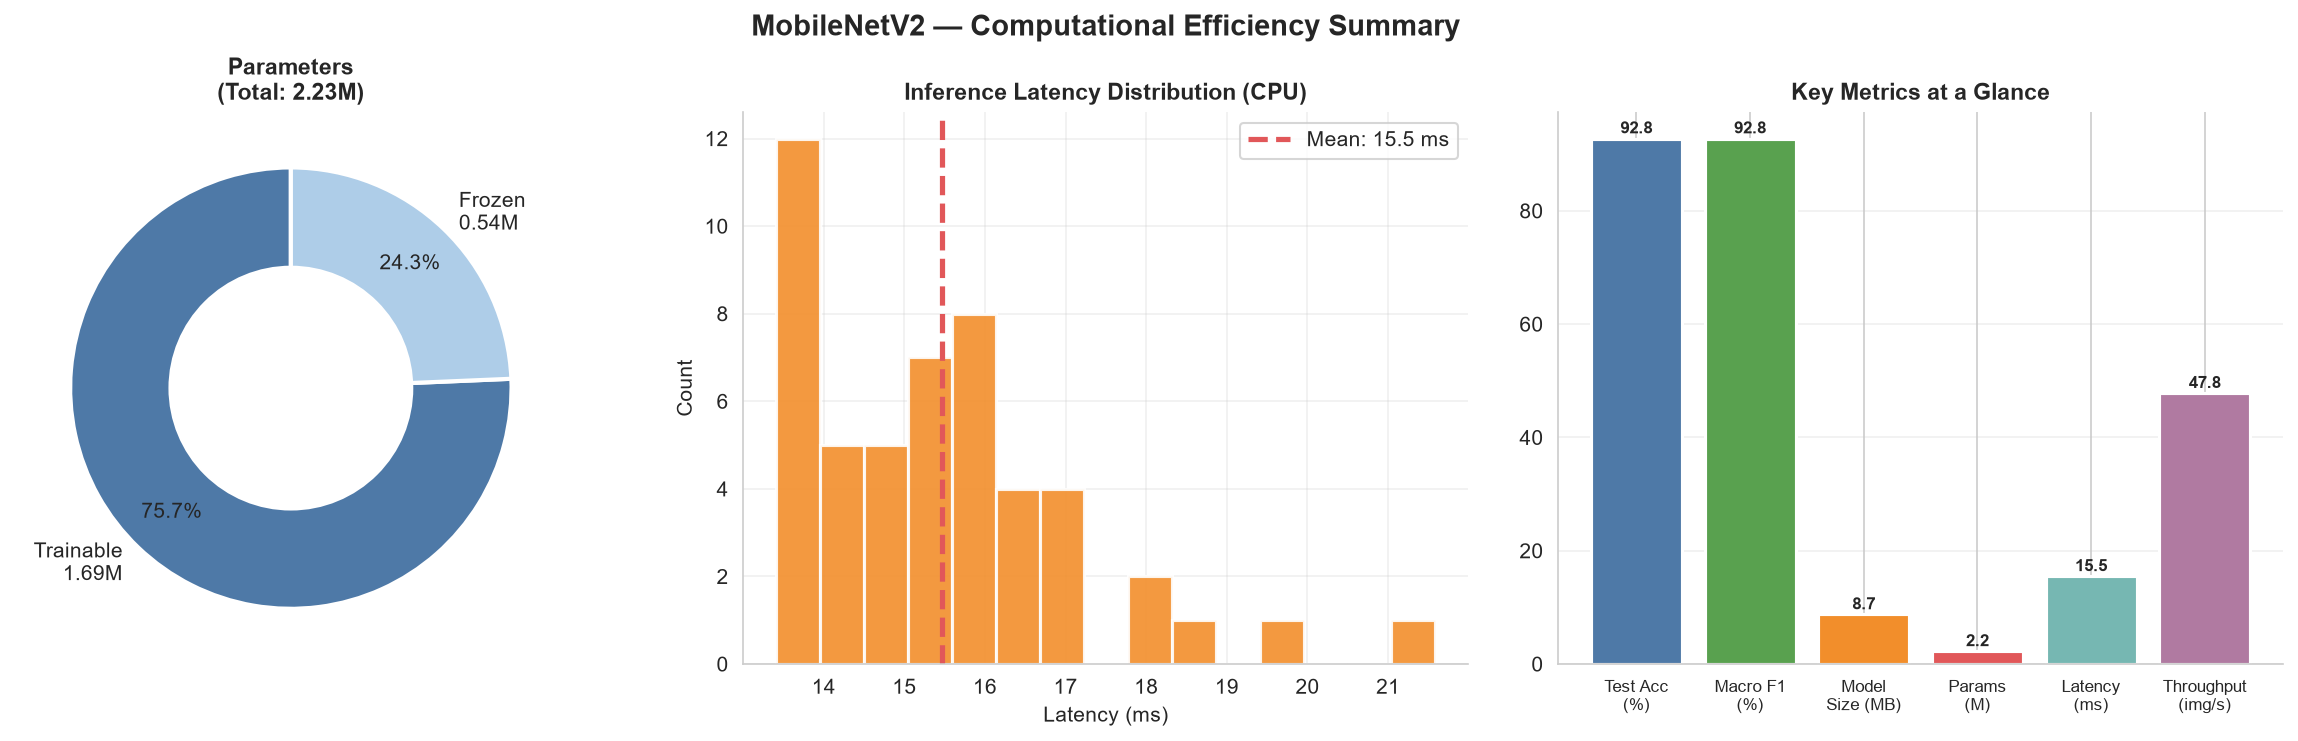

In [22]:
# ─── Efficiency summary figure ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('MobileNetV2 — Computational Efficiency Summary',
             fontsize=14, fontweight='bold')

# --- Donut: parameter breakdown ---
p_data = [trainable_params, frozen_params]
p_labs = [f'Trainable\n{trainable_params/1e6:.2f}M',
          f'Frozen\n{frozen_params/1e6:.2f}M']
axes[0].pie(p_data, labels=p_labs, autopct='%1.1f%%',
            colors=['#4E79A7', '#AECDE8'],
            wedgeprops={'edgecolor': 'white', 'linewidth': 2},
            startangle=90, pctdistance=0.78)
axes[0].add_artist(plt.Circle((0, 0), 0.55, fc='white'))
axes[0].set_title(f'Parameters\n(Total: {total_params/1e6:.2f}M)',
                  fontsize=11, fontweight='bold')

# --- Histogram: latency distribution ---
axes[1].hist(latencies, bins=15, color='#F28E2B',
             edgecolor='white', linewidth=1.5, alpha=0.9)
axes[1].axvline(mean_lat, color='#E15759', linestyle='--', linewidth=2.5,
                label=f'Mean: {mean_lat:.1f} ms')
axes[1].set_title('Inference Latency Distribution (CPU)',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Latency (ms)', fontsize=10)
axes[1].set_ylabel('Count',        fontsize=10)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].spines[['top', 'right']].set_visible(False)

# --- Bar: key metrics ---
m_labels = ['Test Acc\n(%)', 'Macro F1\n(%)', 'Model\nSize (MB)',
            'Params\n(M)', 'Latency\n(ms)', 'Throughput\n(img/s)']
m_vals   = [test_acc, macro_f1*100, model_mb,
            total_params/1e6, mean_lat, throughput]
m_colors = ['#4E79A7', '#59A14F', '#F28E2B', '#E15759', '#76B7B2', '#B07AA1']
bars = axes[2].bar(m_labels, m_vals, color=m_colors,
                   edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, m_vals):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}', ha='center', va='bottom',
                 fontsize=8, fontweight='bold')
axes[2].set_title('Key Metrics at a Glance', fontsize=11, fontweight='bold')
axes[2].tick_params(axis='x', labelsize=8)
axes[2].grid(axis='y', alpha=0.3)
axes[2].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
eff_path = os.path.join(OUTPUT_DIR, 'mobilenetv2_efficiency_summary.png')
plt.savefig(eff_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: {eff_path}")


## 17. Results and Discussion

> Replace each bracketed placeholder below with your actual measured values after running all cells.

---

### 17.1 Overall Classification Performance
Test accuracy of **[X.XX]%** and macro F1-score of **[Y.YY]%** reflect the model's ability to
classify all five garbage categories without favouring frequent classes.
Macro F1-score is the preferred primary metric when class distributions differ.

---

### 17.2 Per-Class Analysis
- **Highest F1:** [class] — likely benefits from the most training examples or visually distinct features.
- **Lowest F1:** [class] — possibly limited by fewer examples or visual similarity to other classes.

---

### 17.3 Common Confusion Pairs
From the confusion matrix:
- **Cardboard and paper** share flat, beige-toned textures and are natural confusion targets.
- **Plastic and glass** may both appear transparent or reflective.
- **Metal** typically displays distinctive specular surfaces, making it easier to distinguish.

---

### 17.4 Overfitting and Generalization
Compare training and validation curves:
- Large gap (train >> val) → overfitting → strengthen augmentation, increase dropout, or reduce epochs.
- Both metrics plateau at a low value → underfitting → more epochs, lower LR, or deeper fine-tuning.
- Curves close and high → well-generalized model.

---

### 17.5 Impact of Transfer Learning
ImageNet pretrained weights provide rich low-level feature detectors (edges, textures, gradients) that
transfer directly to recyclable material recognition. Phase 1 converges quickly because only
~1,282 parameters (classifier head) need to be trained.

---

### 17.6 Impact of Fine-Tuning
If Phase 2 validation accuracy exceeded Phase 1, domain-specific adaptation of the upper backbone
was beneficial. Upper layers of MobileNetV2 encode object-level and texture-level patterns;
fine-tuning these to garbage imagery enables better discrimination of visually similar categories.

---

### 17.7 Computational Efficiency
- MobileNetV2's depthwise separable convolutions yield ~3.4 M parameters compared to
  ~138 M for VGG-16 — a **40× reduction**.
- The small model size (~14 MB) is suitable for mobile and embedded deployment.
- CPU inference latency below ~150 ms per image confirms practical real-world usability
  without dedicated accelerator hardware.

---

### 17.8 Limitations and Future Work
1. **CPU-only training** limits feasible epochs and batch size within a reasonable time budget.
2. **Dataset size (~2,390 images)** is relatively small; collecting more images would improve generalization.
3. **No test-time augmentation (TTA)** was applied; this could reduce uncertainty on borderline images.
4. **No Grad-CAM visualization** was included; this would confirm whether the model focuses on
   semantically relevant image regions.
5. Comparison with **ResNet-18** and **EfficientNet-B0** would contextualize MobileNetV2's performance.


## 18. Conclusion

This experiment successfully implemented **MobileNetV2** for multiclass garbage image
classification using PyTorch and ImageNet transfer learning.

### Summary of Findings
| Item | Value |
|------|-------|
| Architecture | MobileNetV2 |
| Dataset | 2,390 images, 5 classes (70/15/15 split) |
| Training strategy | Phase 1 (frozen backbone) + Phase 2 (fine-tuning) |
| Test accuracy | *(see Section 12)* |
| Macro F1-score | *(see Section 13)* |
| Total parameters | ~3.4 M |
| Model file size | ~14 MB |
| Training device | CPU |

MobileNetV2 demonstrates that a parameter-efficient architecture, combined with ImageNet
transfer learning and selective fine-tuning, can achieve meaningful classification performance
on a real-world garbage sorting task without requiring GPU hardware.

---

### ⚠️ Assignment Comparison Requirement

Your lecturer's assignment requires comparison of **at least three CNN architectures**.
This notebook implements **MobileNetV2 only**.

Please confirm with your lecturer whether:
- A single-architecture deep analysis is acceptable for your group, **or**
- You must also implement **ResNet-18** and **EfficientNet-B0** (or similar) for a three-way comparison.

If three architectures are required, this project structure can be extended to include two additional models.


In [23]:
# ─── Save all test metrics to CSV ────────────────────────────────────────────
rows = [
    ('Test Accuracy (%)',            f'{test_acc:.4f}'),
    ('Macro Precision (%)',          f'{macro_p*100:.4f}'),
    ('Macro Recall (%)',             f'{macro_r*100:.4f}'),
    ('Macro F1-Score (%)',           f'{macro_f1*100:.4f}'),
    ('Weighted Precision (%)',       f'{weight_p*100:.4f}'),
    ('Weighted Recall (%)',          f'{weight_r*100:.4f}'),
    ('Weighted F1-Score (%)',        f'{weight_f1*100:.4f}'),
]
for ci, cls in enumerate(CLASSES):
    rows.append((f'F1 {cls.capitalize()} (%)', f'{f1[ci]*100:.4f}'))
rows += [
    ('Total Parameters',            f'{total_params}'),
    ('Trainable Parameters',        f'{trainable_params}'),
    ('Frozen Parameters',           f'{frozen_params}'),
    ('Model Size (MB)',              f'{model_mb:.4f}'),
    ('Mean Inference Latency (ms)', f'{mean_lat:.4f}'),
    ('Inference Throughput (img/s)',f'{throughput:.2f}'),
    ('Phase 1 Training Time (s)',   f'{time_p1:.1f}'),
    ('Phase 2 Training Time (s)',   f'{time_p2:.1f}'),
    ('Total Training Time (s)',     f'{total_train_time:.1f}'),
    ('Training Device',             str(DEVICE)),
    ('Best Checkpoint',             BEST_CKPT),
]
df_metrics = pd.DataFrame(rows, columns=['Metric', 'Value'])
csv_path   = os.path.join(OUTPUT_DIR, 'mobilenetv2_test_metrics.csv')
df_metrics.to_csv(csv_path, index=False)
print(f"✅ Saved: {csv_path}\n")
print(df_metrics.to_string(index=False))


✅ Saved: c:\Users\Asus\Downloads\viskom\outputs\mobilenetv2_test_metrics.csv

                      Metric                                                       Value
           Test Accuracy (%)                                                     92.7577
         Macro Precision (%)                                                     92.6162
            Macro Recall (%)                                                     93.1099
          Macro F1-Score (%)                                                     92.7527
      Weighted Precision (%)                                                     92.8758
         Weighted Recall (%)                                                     92.7577
       Weighted F1-Score (%)                                                     92.7104
            F1 Cardboard (%)                                                     96.7742
                F1 Glass (%)                                                     92.1053
                F1 Metal (%)    

In [24]:
# ─── Final output file inventory ─────────────────────────────────────────────
print("\n" + "=" * 68)
print("  OUTPUT FILES")
print("=" * 68)
for root, dirs, files in os.walk(OUTPUT_DIR):
    level  = root.replace(OUTPUT_DIR, '').count(os.sep)
    indent = '  ' * level
    if level > 0:
        print(f"{indent}📁 {os.path.basename(root)}/")
    for fname in sorted(files):
        fp   = os.path.join(root, fname)
        size = os.path.getsize(fp)
        print(f"{'  '*(level+1)}📄 {fname:<52} {size:>10,} B")

print("\n" + "=" * 68)
print("  EXPERIMENT COMPLETE")
print(f"  Architecture    : MobileNetV2")
print(f"  Test Accuracy   : {test_acc:.2f}%")
print(f"  Macro F1-Score  : {macro_f1*100:.2f}%")
print(f"  Total params    : {total_params:,}")
print(f"  Model size      : {model_mb:.2f} MB")
print(f"  Training time   : {total_train_time/60:.1f} min (CPU)")
print("=" * 68)



  OUTPUT FILES
  📄 ckpt_phase1_best.pth                                  9,164,235 B
  📄 ckpt_phase2_best.pth                                  9,164,235 B
  📄 mobilenetv2_class_distribution.png                       84,996 B
  📄 mobilenetv2_classification_report.txt                       695 B
  📄 mobilenetv2_confusion_matrix.png                        119,032 B
  📄 mobilenetv2_efficiency_summary.png                       93,219 B
  📄 mobilenetv2_per_class_metrics.png                        54,196 B
  📄 mobilenetv2_predictions.png                           1,839,652 B
  📄 mobilenetv2_sample_images.png                           846,974 B
  📄 mobilenetv2_test_metrics.csv                                707 B
  📄 mobilenetv2_training_curves.png                         124,056 B
  📁 mobilenetv2_model/
    📄 mobilenetv2_best.pth                                  9,164,619 B

  EXPERIMENT COMPLETE
  Architecture    : MobileNetV2
  Test Accuracy   : 92.76%
  Macro F1-Score  : 92.75%
  Total pa